# 02_model_08：短期负荷直接预测、模型比较与气象敏感性分析

本部分围绕“建立回归模型预测短期负荷，并判断气象预报信息是否带来额外收益”展开。目标日为未来一天，输出 144 个 10 分钟负荷点，因此模型直接预测完整日内曲线，而不是先预测一个日级指标再套用固定模板。

全文按以下逻辑组织：

1. 明确分析对象、数据子集和预测任务；
2. 使用相同输入、相同时间切分和相同输出目标训练两个基础回归算法；
3. 用 MSE、RMSE、MAE、sMAPE、归一化 RMSE 和 R²评价两个基础模型，并与前一天、前一周持久性基线比较；
4. 在 Ridge 的基础上加入气象摘要，使用可控的模拟气象噪声检验气象预报接近真实值时是否改善预测；
5. 用负荷曲线、日用电量和气象接近度—预测准确度图展示结果；
6. 最后对数据选择、方法质量、可视化、结论和创新点统一回应，并附上两个基础算法的原理。

## 1. 分析对象、数据选择与预测任务

分析对象是全市三区合计负荷 `Z_total = Z1 + Z2 + Z3`。选择总负荷的理由是：调度首先关心全市电源侧需要承担的总负荷，三区合计还能减弱局部随机波动，更接近实际调度对象。原始记录保持 10 分钟粒度，每个完整日包含 144 个点。

本项目按时间顺序划分数据：2017 年 1 月至 10 月的目标日用于训练，2017 年 11 月至 12 月的目标日用于测试，共评价 60 个未来日。测试集不参与模型拟合，避免把未来信息带回训练过程。只保留时间顺序正确、采样间隔完整且含有 144 个点的日曲线。

预测任务是：在目标日开始前，使用前一天和前一周同日的负荷曲线，加上目标日提前可知的星期、月份和周末特征，预测目标日完整的 144 点负荷曲线。模型是多输出回归模型，不是递归式逐点预测，因此不会把前一个预测值再次作为下一步输入。

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
FIG_DIR = 'figures'
SPLIT = pd.Timestamp('2017-11-01')
MODEL_NAMES = ['Ridge多输出回归', 'ExtraTrees多输出回归']
print('预测频率：10分钟；预测步长：1天；输出点数：144')

预测频率：10分钟；预测步长：1天；输出点数：144


### 1.1 数据读取和完整日曲线

下面读取原始数据，检查时间顺序、采样间隔、缺失值和完整日结构，并构造全市三区合计负荷。

In [6]:
df = pd.read_csv('data/题4_城市电力负荷.csv', encoding='utf-8-sig')
df.columns = ['DateTime', 'T', 'RH', 'WS', 'GDF', 'DF', 'Z1', 'Z2', 'Z3']
df['DateTime'] = pd.to_datetime(df['DateTime'], format='%m/%d/%Y %H:%M')
df = df.set_index('DateTime').sort_index()
df['Z_total'] = df[['Z1', 'Z2', 'Z3']].sum(axis=1)
assert not df.index.duplicated().any()
step_minutes = df.index.to_series().diff().dropna().dt.total_seconds().div(60)
assert step_minutes.eq(10).all()

WEATHER_COLS = ['T', 'RH', 'WS', 'GDF', 'DF']
day_profiles = {}
weather_profiles = {}
for day, group in df.groupby(df.index.normalize()):
    if len(group) == 144:
        day = pd.Timestamp(day)
        day_profiles[day] = group['Z_total'].to_numpy(dtype=float)
        weather_profiles[day] = {col: group[col].to_numpy(dtype=float) for col in WEATHER_COLS}

days = pd.DatetimeIndex(sorted(day_profiles))
print('完整天数:', len(days))
print('采样间隔:', step_minutes.mode().iloc[0], '分钟')

完整天数: 364
采样间隔: 10.0 分钟


## 2. 构造直接多输出预测样本

每个样本对应一个目标日 `D`。无气象基础模型的输入为：

```text
X_D = [D-1 的 144 点负荷曲线,
       D-7 的 144 点负荷曲线,
       目标日星期、月份、是否周末]
```

输出为目标日的 144 个负荷点：

```text
Y_D = [D 日的 144 点负荷曲线]
```

前一天曲线反映最近的负荷状态，前一周同日曲线保留工作日/周末结构；两条曲线共同覆盖短期惯性、日周期和周周期。目标日历特征在预测时已经知道，因此不会造成信息泄漏。

In [7]:
def calendar_features(day):
    day = pd.Timestamp(day)
    return [
        np.sin(2 * np.pi * day.dayofweek / 7),
        np.cos(2 * np.pi * day.dayofweek / 7),
        np.sin(2 * np.pi * (day.month - 1) / 12),
        np.cos(2 * np.pi * (day.month - 1) / 12),
        int(day.dayofweek >= 5),
    ]

X, Y, target_dates = [], [], []
for target_day in days:
    if target_day - pd.Timedelta(days=1) not in day_profiles:
        continue
    if target_day - pd.Timedelta(days=7) not in day_profiles:
        continue
    features = np.concatenate([
        day_profiles[target_day - pd.Timedelta(days=1)],
        day_profiles[target_day - pd.Timedelta(days=7)],
        np.asarray(calendar_features(target_day), dtype=float),
    ])
    X.append(features)
    Y.append(day_profiles[target_day])
    target_dates.append(target_day)

X = np.asarray(X)
Y = np.asarray(Y)
target_dates = pd.DatetimeIndex(target_dates)
train_mask = target_dates < SPLIT
test_mask = target_dates >= SPLIT
X_train, Y_train = X[train_mask], Y[train_mask]
X_test, Y_test = X[test_mask], Y[test_mask]
test_dates = target_dates[test_mask]
print('X_train:', X_train.shape, '| Y_train:', Y_train.shape)
print('X_test:', X_test.shape, '| Y_test:', Y_test.shape)

X_train: (297, 293) | Y_train: (297, 144)
X_test: (60, 293) | Y_test: (60, 144)


## 3. 训练两个基础算法与一个气象增强版本

本项目的核心比较对象是两个基础回归算法：

- **Ridge 多输出回归**：标准化输入后使用 L2 正则化，`alpha=10`。它适合历史曲线变量高度相关、日级样本相对较少的情况；
- **ExtraTrees 多输出回归**：由多棵随机化回归树组成，用于检验非线性划分和特征交互是否能带来额外收益。本版本固定使用 `n_estimators=200`、`max_depth=12`、`min_samples_leaf=2`、`max_features=0.7`；其中树深、叶节点样本数和特征采样比例直接影响模型复杂度，树的数量主要影响集成方差和稳定性。

两种算法使用完全相同的输入、训练集、测试集和 144 点输出目标，因此可以进行条件公平比较。但这里的参数是基线设置，不是通过时间序列交叉验证选出的最优参数；比较结果只能说明“当前参数下”的差异，不能代表所有 Ridge、ExtraTrees 或其他树模型的总体能力。正式建模时，应只在训练期内部用滚动时间验证选择 `alpha`、树深、叶节点样本数和特征采样比例，最后再用锁定的测试集做一次评估。

当前的历史负荷曲线、前一天/前一周滞后和日历特征已经构成合理的强基线。ExtraTrees 表现较弱时，不能直接归因于特征工程失败：本任务只有约 300 个训练日、约 293 个输入特征，且测试期是训练期之后的 11—12 月，样本量和季节分布都可能影响树模型。后续可以在滚动验证中比较曲线归一化、趋势/变化率、节假日和更多气象滞后特征，但这些属于扩展实验。

评价时以 RMSE、MAE 和 sMAPE 作为主要曲线误差指标；R²作为辅助指标，并明确其多输出聚合口径。

In [8]:
models = {
    'Ridge多输出回归': make_pipeline(
        StandardScaler(), Ridge(alpha=10.0)
    ),
    'ExtraTrees多输出回归': ExtraTreesRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=2,
        max_features=0.7,
        n_jobs=1,
        random_state=0,
    ),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, Y_train)
    predictions[name] = model.predict(X_test)
print('两个基础算法模型训练完成')

两个基础算法模型训练完成


## 4. 两个基础模型的指标评价

本节主要用 RMSE、MAE 和 sMAPE 判断完整 144 点负荷曲线的预测误差，并把 R²作为辅助信息。当前测试集为 2017-11-01 至 2017-12-30，共 60 个目标日。

在当前固定参数和这一个时间外推测试窗内，Ridge 的 RMSE 为 2,442.59 kW，ExtraTrees 为 3,902.17 kW；MAE 为 1,708.31 kW 对 3,118.29 kW；sMAPE 为 2.65% 对 4.73%。因此可以严谨地说：**在当前测试区间和当前参数下，Ridge 的预测误差明显低于 ExtraTrees**。这不是“线性模型必然优于树模型”的普遍结论，也不能直接推广到其他季节、其他年份或其他树模型。

代码中的 `r2_score(Y_test, pred)` 使用 sklearn 默认的多输出口径：先对 144 个时间点分别计算跨测试日的 R²，再取平均。因此表中的“逐时间点平均 R²”是 Ridge=0.3258、ExtraTrees=-1.5197，不能直接称为整条曲线展平后的总体 R²。代码同时报告“曲线展平 R²”，即把 60×144 个点展平后计算的 R²；当前结果约为 Ridge=0.9705、ExtraTrees=0.9246。两种口径回答的问题不同，不能混用。

In [9]:
def smape(y_true, pred):
    return np.mean(2 * np.abs(pred - y_true) /
                   (np.abs(y_true) + np.abs(pred) + 1e-9)) * 100

metric_rows = []
for name, pred in predictions.items():
    mse = mean_squared_error(Y_test, pred)
    metric_rows.append({
        '模型': name,
        '曲线MSE(kW²)': mse,
        '曲线RMSE(kW)': np.sqrt(mse),
        '曲线MAE(kW)': mean_absolute_error(Y_test, pred),
        '曲线sMAPE%': smape(Y_test, pred),
        '曲线归一化RMSE%': np.sqrt(mse) / np.mean(np.abs(Y_test)) * 100,
        '曲线逐时间点平均R2': r2_score(Y_test, pred),
        '曲线展平R2': r2_score(Y_test.ravel(), pred.ravel()),
    })

summary_rows = []
for name, pred in predictions.items():
    for label, fn in [('日用电量(kWh)', lambda x: x.sum(axis=1) / 6),
                      ('日峰值(kW)', lambda x: x.max(axis=1)),
                      ('日谷值(kW)', lambda x: x.min(axis=1))]:
        y_true, y_pred = fn(Y_test), fn(pred)
        mse = mean_squared_error(y_true, y_pred)
        summary_rows.append({
            '模型': name,
            '目标': label,
            'MSE': mse,
            'RMSE': np.sqrt(mse),
            'MAE': mean_absolute_error(y_true, y_pred),
            'sMAPE%': smape(y_true, y_pred),
            '归一化RMSE%': np.sqrt(mse) / np.mean(np.abs(y_true)) * 100,
            'R2': r2_score(y_true, y_pred),
        })

curve_metrics = pd.DataFrame(metric_rows)
summary_metrics = pd.DataFrame(summary_rows)
display(curve_metrics.style.format({
    '曲线MSE(kW²)': '{:,.0f}', '曲线RMSE(kW)': '{:,.2f}',
    '曲线MAE(kW)': '{:,.2f}', '曲线sMAPE%': '{:.2f}%',
    '曲线归一化RMSE%': '{:.2f}%', '曲线逐时间点平均R2': '{:.4f}', '曲线展平R2': '{:.4f}'
}))
display(summary_metrics.style.format({
    'MSE': '{:,.0f}', 'RMSE': '{:,.2f}', 'MAE': '{:,.2f}',
    'sMAPE%': '{:.2f}%', '归一化RMSE%': '{:.2f}%', 'R2': '{:.4f}'
}))

,模型,曲线MSE(kW²),曲线RMSE(kW),曲线MAE(kW),曲线sMAPE%,曲线归一化RMSE%,曲线逐时间点平均R2,曲线展平R2
0,Ridge多输出回归,"5,966,236","2,442.59","1,708.31",2.65%,3.79%,0.3258,0.9705
1,ExtraTrees多输出回归,"15,226,917","3,902.17","3,118.29",4.73%,6.06%,-1.5197,0.9246


,模型,目标,MSE,RMSE,MAE,sMAPE%,归一化RMSE%,R2
0,Ridge多输出回归,日用电量(kWh),"1,259,278,331","35,486.31","26,115.65",1.69%,2.29%,0.5731
1,Ridge多输出回归,日峰值(kW),"6,792,452","2,606.23","2,005.66",2.23%,2.91%,0.3455
2,Ridge多输出回归,日谷值(kW),"5,688,286","2,385.01","1,609.44",3.72%,5.40%,0.4808
3,ExtraTrees多输出回归,日用电量(kWh),"4,066,634,249","63,770.17","52,889.59",3.41%,4.12%,-0.3787
4,ExtraTrees多输出回归,日峰值(kW),"20,656,482","4,544.94","3,841.86",4.25%,5.07%,-0.9904
5,ExtraTrees多输出回归,日谷值(kW),"15,094,329","3,885.14","3,365.16",7.50%,8.80%,-0.3777


## 5. 与前一天、前一周持久性基线比较

前一天和前一周曲线不是训练出来的时间序列模型，而是无需拟合参数的业务基线：

```text
前一天基线：ŷ_D = y_{D-1}
前一周基线：ŷ_D = y_{D-7}
```

在 2017-11-01 至 2017-12-30 这个测试窗内，Ridge 的曲线 RMSE 为 2,442.59 kW，低于前一天基线的 3,232.75 kW 和前一周基线的 2,986.68 kW；MAE、sMAPE 和归一化 RMSE 也低于两个基线。因此，Ridge 在这个测试区间获得了超过简单持久性规则的预测增益。ExtraTrees 的 RMSE 为 3,902.17 kW，没有超过任一基线。

这里的结论仍然是条件性的：测试集只有年末 60 天，且训练期与测试期存在季节分布变化。它支持“Ridge 在当前测试窗内有增量价值”，不支持“Ridge 在所有时期都一定优于树模型”。R²表中的“逐时间点平均 R²”和“曲线展平 R²”分别对应不同聚合口径，应结合 RMSE、MAE 和 sMAPE 一起解读。

In [10]:
baseline_rows = []
for name, lag in [('前一天曲线基线', 1), ('前一周曲线基线', 7)]:
    baseline = np.asarray([day_profiles[d - pd.Timedelta(days=lag)] for d in test_dates])
    mse = mean_squared_error(Y_test, baseline)
    baseline_rows.append({
        '模型': name,
        '曲线MSE(kW²)': mse,
        '曲线RMSE(kW)': np.sqrt(mse),
        '曲线MAE(kW)': mean_absolute_error(Y_test, baseline),
        '曲线sMAPE%': smape(Y_test, baseline),
        '曲线归一化RMSE%': np.sqrt(mse) / np.mean(np.abs(Y_test)) * 100,
        '曲线逐时间点平均R2': r2_score(Y_test, baseline),
        '曲线展平R2': r2_score(Y_test.ravel(), baseline.ravel()),
    })
baseline_metrics = pd.DataFrame(baseline_rows)
all_curve_metrics = pd.concat([curve_metrics, baseline_metrics], ignore_index=True)
display(all_curve_metrics.style.format({
    '曲线MSE(kW²)': '{:,.0f}', '曲线RMSE(kW)': '{:,.2f}',
    '曲线MAE(kW)': '{:,.2f}', '曲线sMAPE%': '{:.2f}%',
    '曲线归一化RMSE%': '{:.2f}%', '曲线逐时间点平均R2': '{:.4f}', '曲线展平R2': '{:.4f}'
}))

,模型,曲线MSE(kW²),曲线RMSE(kW),曲线MAE(kW),曲线sMAPE%,曲线归一化RMSE%,曲线逐时间点平均R2,曲线展平R2
0,Ridge多输出回归,"5,966,236","2,442.59","1,708.31",2.65%,3.79%,0.3258,0.9705
1,ExtraTrees多输出回归,"15,226,917","3,902.17","3,118.29",4.73%,6.06%,-1.5197,0.9246
2,前一天曲线基线,"10,450,647","3,232.75","2,122.43",3.41%,5.02%,-0.0419,0.9483
3,前一周曲线基线,"8,920,256","2,986.68","2,150.35",3.40%,4.64%,-0.1068,0.9558


## 6. 气象增强模型与模拟气象预报敏感性

在 Ridge 的历史负荷和日历输入中加入温度 `T`、湿度 `RH`、风速 `WS`、总散射辐射 `GDF` 和散射辐射 `DF` 的目标日摘要，得到 Ridge-气象增强模型。算法仍然是 Ridge，变化的是输入信息。

训练阶段使用训练期目标日已实现的真实气象值作为训练特征，学习气象与负荷之间的关系；测试阶段不把目标日真实气象直接当作可部署的预报，而是构造不同接近度的模拟气象，因此训练特征与测试预报之间存在预报误差造成的分布差异：

```text
模拟气象 = 前一日气象 + 接近度 ×（目标日真实气象 − 前一日气象）
```

接近度为 0% 时使用前一日持久性气象，接近度为 50% 时修正一半差距，接近度为 100% 时使用目标日真实气象，作为理想信息参考。这里的 100% 情景是事后构造的 oracle 参考，不是实际部署性能；不同接近度的结果也不是因果实验，而是对气象预报误差敏感性的情景分析。

`weather_error_basis` 只用于展示训练期持久性天气误差的尺度，当前代码的测试情景采用确定性插值，并没有把该表中的误差随机抽样成真实预报噪声。因此后续若要模拟真实预报，应使用历史预报数据或明确的误差分布。

In [11]:
def weather_summary(day_weather):
    return np.concatenate([
        np.array([day_weather[col].mean(), day_weather[col].max(), day_weather[col].min()])
        for col in WEATHER_COLS
    ])

def load_curve_features(target_day):
    return np.concatenate([
        day_profiles[target_day - pd.Timedelta(days=1)],
        day_profiles[target_day - pd.Timedelta(days=7)],
        np.asarray(calendar_features(target_day), dtype=float),
    ])

# 训练期持久性天气误差：用于展示误差尺度；当前测试情景采用确定性插值，不直接抽样该误差表。
weather_error_rows = []
for target_day in days:
    if target_day >= SPLIT or target_day - pd.Timedelta(days=1) not in weather_profiles:
        continue
    for col in WEATHER_COLS:
        error = weather_profiles[target_day - pd.Timedelta(days=1)][col] - weather_profiles[target_day][col]
        weather_error_rows.append({
            '目标日': target_day, '变量': col,
            'MAE': np.mean(np.abs(error)),
            'RMSE': np.sqrt(np.mean(error ** 2)),
        })
weather_error_basis = pd.DataFrame(weather_error_rows).groupby('变量', as_index=False).agg(
    训练期MAE=('MAE', 'mean'), 训练期RMSE=('RMSE', 'mean')
)
display(weather_error_basis.style.format({'训练期MAE': '{:,.3f}', '训练期RMSE': '{:,.3f}'}))

# 训练阶段使用目标日真实天气，学习天气与负荷之间的关系。
Xw_train, Yw_train = [], []
for target_day in target_dates[train_mask]:
    actual_weather = {col: weather_profiles[target_day][col] for col in WEATHER_COLS}
    Xw_train.append(np.r_[load_curve_features(target_day), weather_summary(actual_weather)])
    Yw_train.append(day_profiles[target_day])
Xw_train, Yw_train = np.asarray(Xw_train), np.asarray(Yw_train)
weather_model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
weather_model.fit(Xw_train, Yw_train)

similarity_levels = [0.0, 0.25, 0.50, 0.75, 1.0]
weather_predictions = {}
weather_gap_rows = []
weather_metric_rows = []
for similarity in similarity_levels:
    Xw_test = []
    gap_values = {col: [] for col in WEATHER_COLS}
    for target_day in test_dates:
        base_weather = {col: weather_profiles[target_day - pd.Timedelta(days=1)][col] for col in WEATHER_COLS}
        actual_weather = {col: weather_profiles[target_day][col] for col in WEATHER_COLS}
        simulated_weather = {}
        for col in WEATHER_COLS:
            simulated_weather[col] = base_weather[col] + similarity * (actual_weather[col] - base_weather[col])
            gap_values[col].extend(simulated_weather[col] - actual_weather[col])
        Xw_test.append(np.r_[load_curve_features(target_day), weather_summary(simulated_weather)])

    pred = weather_model.predict(np.asarray(Xw_test))
    weather_predictions[similarity] = pred
    for col in WEATHER_COLS:
        gap = np.asarray(gap_values[col])
        weather_gap_rows.append({
            '气象接近度%': similarity * 100,
            '变量': col,
            '模拟预报MAE': np.mean(np.abs(gap)),
            '模拟预报RMSE': np.sqrt(np.mean(gap ** 2)),
        })
    mse = mean_squared_error(Y_test, pred)
    weather_metric_rows.append({
        '模型': 'Ridge-真实气象' if similarity == 1.0 else 'Ridge-模拟气象',
        '气象接近度%': similarity * 100,
        '曲线MSE(kW²)': mse,
        '曲线RMSE(kW)': np.sqrt(mse),
        '曲线MAE(kW)': mean_absolute_error(Y_test, pred),
        '曲线sMAPE%': smape(Y_test, pred),
        '曲线归一化RMSE%': np.sqrt(mse) / np.mean(np.abs(Y_test)) * 100,
        '曲线逐时间点平均R2': r2_score(Y_test, pred),
        '曲线展平R2': r2_score(Y_test.ravel(), pred.ravel()),
        '日用电量RMSE(kWh)': np.sqrt(np.mean((Y_test.sum(axis=1) / 6 - pred.sum(axis=1) / 6) ** 2)),
        '日用电量sMAPE%': smape(Y_test.sum(axis=1) / 6, pred.sum(axis=1) / 6),
    })

weather_gap_df = pd.DataFrame(weather_gap_rows)
weather_metrics_df = pd.DataFrame(weather_metric_rows)
print('测试集持久性天气预报误差（气象接近度 0%）：')
display(weather_gap_df[weather_gap_df['气象接近度%'] == 0].style.format({
    '模拟预报MAE': '{:,.3f}', '模拟预报RMSE': '{:,.3f}'
}))
print('Ridge-模拟气象：不同接近度下的测试效果')
display(weather_metrics_df[weather_metrics_df['气象接近度%'] < 100].style.format({
    '气象接近度%': '{:.0f}%', '曲线MSE(kW²)': '{:,.0f}',
    '曲线RMSE(kW)': '{:,.2f}', '曲线MAE(kW)': '{:,.2f}',
    '曲线sMAPE%': '{:.2f}%', '曲线归一化RMSE%': '{:.2f}%',
    '曲线逐时间点平均R2': '{:.4f}', '曲线展平R2': '{:.4f}', '日用电量RMSE(kWh)': '{:,.2f}',
    '日用电量sMAPE%': '{:.2f}%'
}))
print('Ridge-真实气象理想参考：')
display(weather_metrics_df[weather_metrics_df['气象接近度%'] == 100].style.format({
    '气象接近度%': '{:.0f}%', '曲线MSE(kW²)': '{:,.0f}',
    '曲线RMSE(kW)': '{:,.2f}', '曲线MAE(kW)': '{:,.2f}',
    '曲线sMAPE%': '{:.2f}%', '曲线归一化RMSE%': '{:.2f}%',
    '曲线逐时间点平均R2': '{:.4f}', '曲线展平R2': '{:.4f}', '日用电量RMSE(kWh)': '{:,.2f}',
    '日用电量sMAPE%': '{:.2f}%'
}))

,变量,训练期MAE,训练期RMSE
0,DF,37.365,71.584
1,GDF,53.237,102.462
2,RH,10.428,12.418
3,T,1.659,1.995
4,WS,0.582,0.842


测试集持久性天气预报误差（气象接近度 0%）：


,气象接近度%,变量,模拟预报MAE,模拟预报RMSE
0,0.000000,T,2.022,2.850
1,0.000000,RH,9.643,12.753
2,0.000000,WS,0.722,1.854
3,0.000000,GDF,30.950,79.475
4,0.000000,DF,22.946,58.216


Ridge-模拟气象：不同接近度下的测试效果


,模型,气象接近度%,曲线MSE(kW²),曲线RMSE(kW),曲线MAE(kW),曲线sMAPE%,曲线归一化RMSE%,曲线逐时间点平均R2,曲线展平R2,日用电量RMSE(kWh),日用电量sMAPE%
0,Ridge-模拟气象,0%,"6,222,532","2,494.50","1,767.05",2.72%,3.87%,0.2550,0.9692,"35,396.08",1.70%
1,Ridge-模拟气象,25%,"6,280,987","2,506.19","1,772.25",2.72%,3.89%,0.2428,0.9689,"35,542.41",1.68%
2,Ridge-模拟气象,50%,"6,326,334","2,515.22","1,776.89",2.73%,3.90%,0.2357,0.9687,"35,703.76",1.69%
3,Ridge-模拟气象,75%,"6,353,764","2,520.67","1,779.22",2.74%,3.91%,0.2336,0.9685,"35,923.06",1.69%


Ridge-真实气象理想参考：


,模型,气象接近度%,曲线MSE(kW²),曲线RMSE(kW),曲线MAE(kW),曲线sMAPE%,曲线归一化RMSE%,曲线逐时间点平均R2,曲线展平R2,日用电量RMSE(kWh),日用电量sMAPE%
4,Ridge-真实气象,100%,"6,341,460","2,518.23","1,777.91",2.74%,3.91%,0.2365,0.9686,"36,077.48",1.69%


## 7. 气象接近度与预测准确度

图 4 左图的横轴是模拟气象接近度，纵轴是预测准确度。代码使用 `100 - sMAPE` 作为可视化分数，因此纵轴越高表示相对误差越小；它是误差的互补分数，不是分类任务中的概率准确率。右图展示不同气象变量的模拟预报 RMSE。

当前测试结果为：无气象 Ridge 的曲线 RMSE 约为 2,442.59 kW；Ridge-模拟气象在 0% 接近度时约为 2,494.50 kW，50% 时约为 2,515.22 kW，100% 理想真实气象参考约为 2,518.23 kW。也就是说，在当前一年数据、当前气象摘要和当前模拟方式下，气象增强版本没有超过纯历史负荷 Ridge，接近度提高也没有带来单调改善。

这个结果不能推出“气象对负荷没有作用”。由于模型训练使用了目标日真实气象，而测试阶段使用了前一日气象到真实气象之间的模拟情景，结果同时受到特征摘要、训练/测试气象分布差异和模拟方式的影响。更准确的表述是：**当前气象输入形式和模拟预报情景没有显示出稳定的边际预测增益**。要评价真实部署价值，应使用历史气象预报或回放数据，并在时间滚动验证中重新训练和评估。

C:\Users\lenovo\AppData\Local\Temp\ipykernel_20524\732699084.py:22: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.suptitle('图4  Ridge-模拟气象的敏感性分析', y=1.02); fig.tight_layout()
C:\Users\lenovo\AppData\Local\Temp\ipykernel_20524\732699084.py:23: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.savefig(f'{FIG_DIR}/fig_B08_weather_sensitivity.png', dpi=160, bbox_inches='tight'); plt.show()
D:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


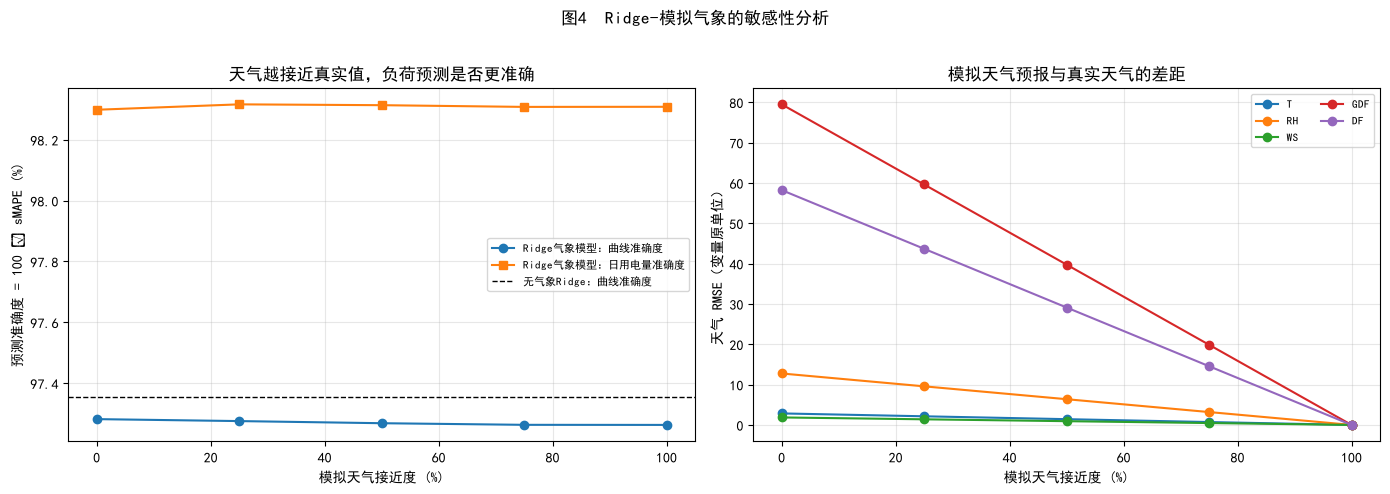

In [12]:
# 图4：气象预报接近度、天气误差和负荷预测准确度
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
# 纵轴使用 100%-sMAPE，越高表示预测越准确。
weather_curve = weather_metrics_df.copy()
weather_curve['曲线准确度%'] = 100 - weather_curve['曲线sMAPE%']
axes[0].plot(weather_curve['气象接近度%'], weather_curve['曲线准确度%'], marker='o', label='Ridge气象模型：曲线准确度')
axes[0].plot(weather_curve['气象接近度%'], 100 - weather_curve['日用电量sMAPE%'], marker='s', label='Ridge气象模型：日用电量准确度')
no_weather_acc = 100 - curve_metrics.loc[curve_metrics['模型'] == 'Ridge多输出回归', '曲线sMAPE%'].iloc[0]
axes[0].axhline(no_weather_acc, color='black', ls='--', lw=1.0, label='无气象Ridge：曲线准确度')
axes[0].set_xlabel('模拟天气接近度 (%)')
axes[0].set_ylabel('预测准确度 = 100 − sMAPE (%)')
axes[0].set_title('天气越接近真实值，负荷预测是否更准确')
axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)

for col in WEATHER_COLS:
    sub = weather_gap_df[weather_gap_df['变量'] == col]
    axes[1].plot(sub['气象接近度%'], sub['模拟预报RMSE'], marker='o', label=col)
axes[1].set_xlabel('模拟天气接近度 (%)')
axes[1].set_ylabel('天气 RMSE（变量原单位）')
axes[1].set_title('模拟天气预报与真实天气的差距')
axes[1].grid(alpha=0.3); axes[1].legend(ncol=2, fontsize=8)
fig.suptitle('图4  Ridge-模拟气象的敏感性分析', y=1.02); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B08_weather_sensitivity.png', dpi=160, bbox_inches='tight'); plt.show()

## 8. 测试集可视化与结果解释

本节代码生成四类互相补充的图：

1. **测试日 144 点曲线图**：同时展示真实负荷、Ridge、ExtraTrees、Ridge-模拟气象和前一周基线，直接观察峰谷位置、幅值偏差和局部波动；
2. **测试期日用电量图**：展示真实日用电量与各模型预测值，观察持续高估、低估和季节漂移；
3. **百分比指标对比图**：用归一化 RMSE 和日用电量 sMAPE 比较模型，避免只看 kW 绝对值；
4. **气象敏感性图**：用接近度—准确度曲线和天气误差曲线检验气象预报质量的影响。

曲线图是判断“是否跟随真实负荷形状”的最直观证据，指标图则把全测试集上的平均表现进行汇总。两者结合可以避免只凭某一个测试日或某一个指标下结论。

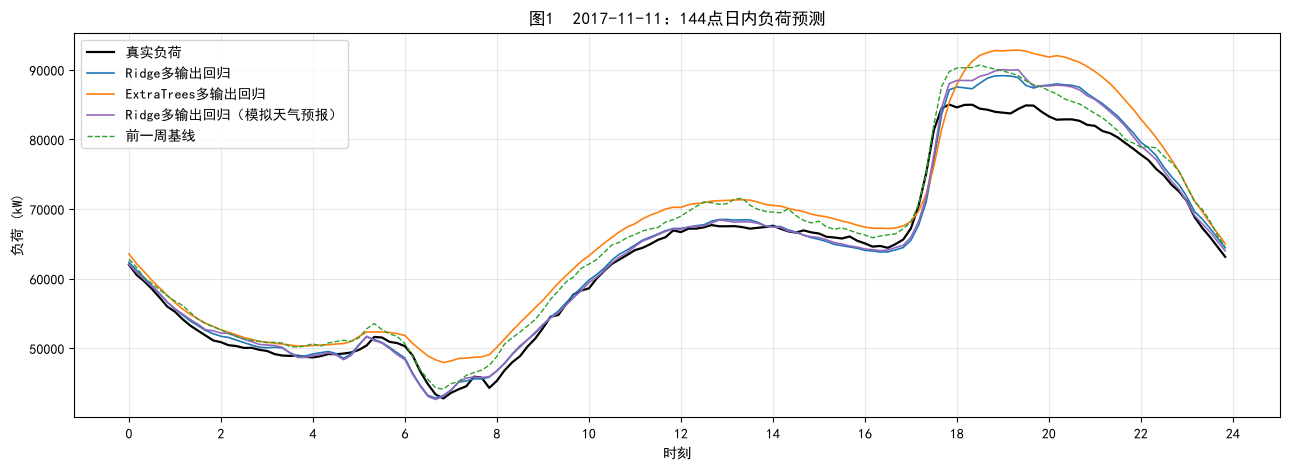

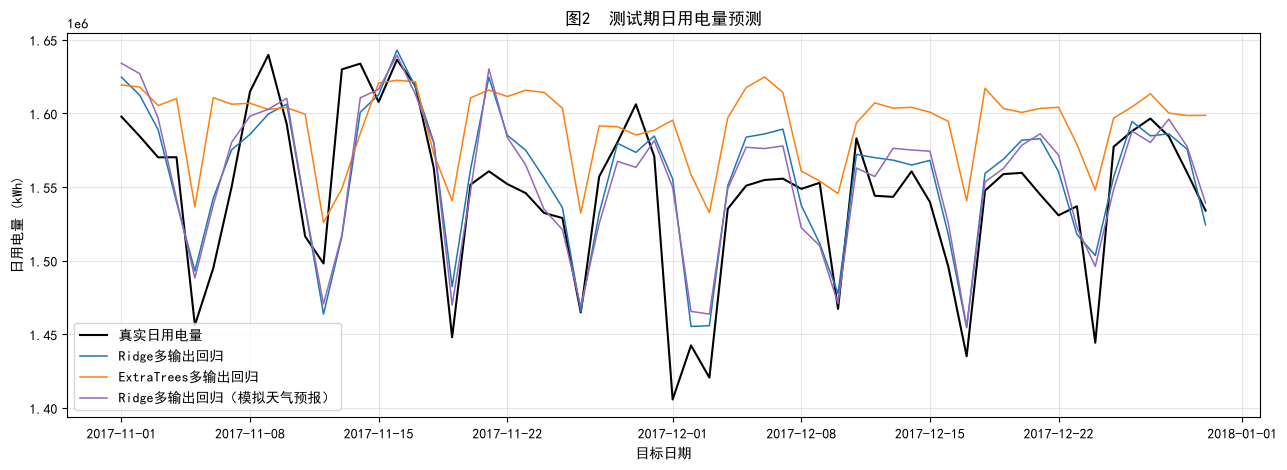

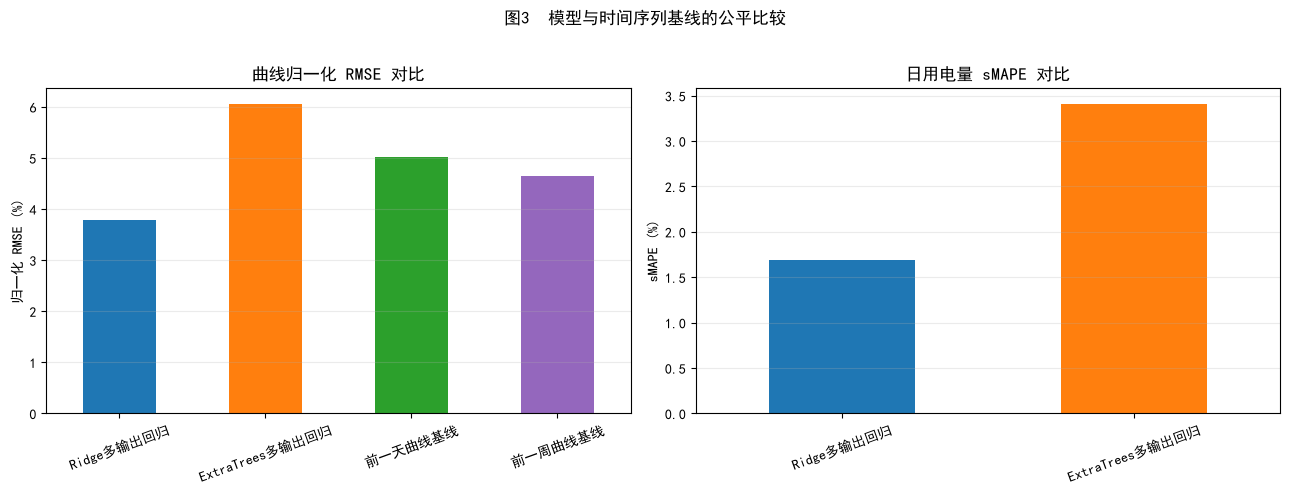

In [13]:
# 图1：测试集某一天的完整预测曲线
example_idx = min(10, len(test_dates) - 1)
slot_axis = np.arange(144) / 6
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(slot_axis, Y_test[example_idx], color='black', lw=1.6, label='真实负荷')
for name, color in [('Ridge多输出回归', '#1f77b4'), ('ExtraTrees多输出回归', '#ff7f0e')]:
    ax.plot(slot_axis, predictions[name][example_idx], color=color, lw=1.2, label=name)
# 模拟天气预报采用气象接近度 0%，即前一天持久性天气。
ax.plot(slot_axis, weather_predictions[0.0][example_idx], color='#9467bd', lw=1.2, label='Ridge多输出回归（模拟天气预报）')
ax.plot(slot_axis, day_profiles[test_dates[example_idx] - pd.Timedelta(days=7)],
        color='#2ca02c', ls='--', lw=1.0, label='前一周基线')
ax.set_title(f'图1  {test_dates[example_idx].date()}：144点日内负荷预测')
ax.set_xlabel('时刻'); ax.set_ylabel('负荷 (kW)')
ax.set_xticks(range(0, 25, 2)); ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B08_curve.png', dpi=160, bbox_inches='tight'); plt.show()

# 图2：测试期日用电量对比
fig, ax = plt.subplots(figsize=(13, 4.8))
actual_energy = Y_test.sum(axis=1) / 6
ax.plot(test_dates, actual_energy, color='black', lw=1.5, label='真实日用电量')
for name, color in [('Ridge多输出回归', '#1f77b4'), ('ExtraTrees多输出回归', '#ff7f0e')]:
    ax.plot(test_dates, predictions[name].sum(axis=1) / 6, color=color, lw=1.1, label=name)
ax.plot(test_dates, weather_predictions[0.0].sum(axis=1) / 6, color='#9467bd', lw=1.1, label='Ridge多输出回归（模拟天气预报）')
ax.set_title('图2  测试期日用电量预测')
ax.set_xlabel('目标日期'); ax.set_ylabel('日用电量 (kWh)')
ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B08_energy.png', dpi=160, bbox_inches='tight'); plt.show()

# 图3：公平的百分比指标对比
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
all_curve_metrics.plot(x='模型', y='曲线归一化RMSE%', kind='bar', ax=axes[0],
                       color=['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd'], legend=False)
axes[0].set_title('曲线归一化 RMSE 对比'); axes[0].set_ylabel('归一化 RMSE (%)'); axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=20); axes[0].grid(alpha=0.25, axis='y')
summary_plot = summary_metrics[summary_metrics['目标'] == '日用电量(kWh)']
summary_plot.plot(x='模型', y='sMAPE%', kind='bar', ax=axes[1],
                  color=['#1f77b4', '#ff7f0e'], legend=False)
axes[1].set_title('日用电量 sMAPE 对比'); axes[1].set_ylabel('sMAPE (%)'); axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=20); axes[1].grid(alpha=0.25, axis='y')
fig.suptitle('图3  模型与时间序列基线的公平比较', y=1.02); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B08_metrics.png', dpi=160, bbox_inches='tight'); plt.show()

## 9. 总结：对六项要求的统一回应

### 9.1 建模与指标评估

本项目建立了直接预测未来一天 144 个 10 分钟负荷点的多输出回归任务，比较了 Ridge 和一组固定参数的 ExtraTrees，并使用 RMSE、MAE、sMAPE、归一化 RMSE 和两种明确标注的 R²口径进行评价。在 2017-11-01 至 2017-12-30 这一个严格时间外推测试窗内，Ridge 的主要误差指标明显低于当前 ExtraTrees 配置。

### 9.2 数据分析的全面性与深度

分析对象是全市三区总负荷，保留 10 分钟粒度并只使用完整日曲线。输入包含前一天和前一周同日曲线，以及预测时已知的日历特征。前一天和前一周基线用于检验模型是否超过简单复制规则。需要明确的是，数据只有 2017-01-01 至 2017-12-30 的 364 个完整日，最终测试窗为 60 天；训练期和测试期存在季节分布变化。

### 9.3 方法选择、运用与评估质量

Ridge 用 L2 正则化处理高度相关的历史曲线变量，ExtraTrees 用作非线性对照。当前结果支持“Ridge 在本测试窗和当前参数下更好”，不支持“线性模型普遍优于树模型”或“树模型不适合负荷预测”。ExtraTrees 的复杂度参数和 Ridge 的 `alpha` 都应在训练期内部用滚动时间交叉验证选择；最终测试集应保持锁定，避免用测试集反复调参。当前历史负荷和日历特征已经是合理的强基线，ExtraTrees 的结果较弱不等于特征工程已经失败。

### 9.4 可视化有效性

测试日曲线图展示局部峰谷和幅值跟踪，测试期日用电量图展示整体趋势，归一化 RMSE/sMAPE 图展示模型横向比较，气象敏感性图展示模拟预报情景下的误差变化。正式提交前应重启内核、清空旧输出并从头运行，确认当前代码生成的表格和 `fig_B08_*` 图文件与 notebook 内容一致。

### 9.5 结论论证、独立思考与创新性

更严谨的总结是：在当前一年数据和 2017 年 11—12 月测试窗内，Ridge 多输出回归的预测误差低于当前 ExtraTrees 配置；这一优势与小样本、高维强共线历史曲线，以及测试期季节外推有关。补充的滚动时间诊断显示，不同月份的模型优劣并不完全一致；正式版本应把这项诊断做成 notebook 中可复现的滚动验证表，再据此讨论跨季节泛化。因此还不能断言 Ridge 在其他年份或所有季节都最好。

气象实验应表述为模拟预报敏感性分析。当前气象摘要和确定性接近度情景没有带来稳定增益，但这不等于气象因素没有作用；真实气象预报、更多年份、细粒度天气特征和历史预报回放可能得到不同结果。

## 附录：两个基础算法与模型扩展的原理

### A.1 Ridge 多输出回归（本项目比较的是正则化 Ridge，不是未正则化普通最小二乘）

设训练输入矩阵为 `X ∈ R^{n×p}`，目标矩阵为 `Y ∈ R^{n×144}`，系数矩阵为 `B ∈ R^{p×144}`。Ridge 通过最小化残差平方和与 L2 正则项：

```text
min_B ||Y - XB||_F² + α||B||_F²
```

其中 `α` 控制正则化强度，`||·||_F` 是 Frobenius 范数。在标准化和截距单独处理的简化形式下：

```text
B̂ = (XᵀX + αI)⁻¹ XᵀY
ŷ = xB̂
```

L2 正则化会压缩过大的回归系数，缓解前一天与前一周曲线之间的共线性。多输出形式让一个模型同时学习 144 个时间点的输出关系。

### A.2 ExtraTrees 多输出回归

ExtraTrees 由多棵随机化回归树组成。每棵树通过随机选择候选特征和切分阈值划分样本，叶节点保存该叶内训练样本的 144 维目标均值向量。若第 `t` 棵树的预测为 `f_t(x)`，集成预测为：

```text
ŷ = (1/T) Σ(t=1 到 T) f_t(x)
```

树模型能够表达非线性和变量交互，但也更容易在样本较少、输入维度较高的情况下形成不稳定划分。本项目通过固定树深、叶节点最小样本数和特征比例控制复杂度，但这些参数尚未通过训练期滚动时间交叉验证优化；测试结果只能说明当前配置没有超过 Ridge 和持久性基线。

### A.3 气象增强和基线不是新的基本算法

气象增强模型仍使用 Ridge，只把气象摘要 `w_D` 拼接到输入：

```text
x_weather = [D-1 曲线, D-7 曲线, 日历特征, w_D]
ŷ_weather = x_weather B̂_weather
```

前一天和前一周基线不训练参数，分别按 `ŷ_D = y_{D-1}` 和 `ŷ_D = y_{D-7}` 生成预测。它们的作用是提供实际可用的强参照，用于判断训练模型是否学习到了简单复制规则之外的统计关系。